# Anomaly detection lab

**The question.** Factories watch their machines with dozens of sensors. When something goes wrong, the readings change. Deep learning is often used to spot those changes, but simple statistics often do just as well. This project asks: **when is deep learning actually worth it?**

This notebook is the place to look at the data and try things. Run it top to bottom (*Run → Run All*). Nothing here uses deep learning yet: this is the "get to know the data and set the bar" phase.

| Section | What you'll see |
|---|---|
| 1. The big idea | Three kinds of fault, and which tool catches which |
| 2. SKAB | The water-pump dataset, in tables and pictures |
| 3. Tennessee Eastman | The chemical-plant dataset, in tables and pictures |
| 4. How a detector is judged | The "1 false alarm in 100" rule, in a picture |
| 5. Simple detectors on both datasets | The bar deep learning has to beat |
| 6. Playground | Change settings, look at other faults, try your own detector |
| 7. What's next | Why we will also generate data |

**Words used throughout**
- **Fault**: a stretch of time when something is wrong (also called an anomaly).
- **Sensor**: one column of readings, such as a temperature, a flow or a vibration.
- **Run**: one recording. In SKAB, one experiment; in the chemical plant, one simulated 48 hours.
- **Normal data**: readings where nothing is wrong. Every detector learns what "normal" looks like from these.
- **Detector**: a method that gives every moment a *weirdness score*.
- **False alarm**: a high score when nothing is wrong.
- **Catch rate**: the share of fault moments that get a high score.

The helper code lives in the `adlab/` folder; this notebook only calls it.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from adlab import data, detectors, metrics, explore, plots, run

pd.set_option("display.float_format", "{:.4g}".format)   # numbers to 4 significant figures, no 1e-04 notation
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)

# Downloads the two datasets into data/raw/ the first time (about 30 MB); later runs skip this.
data.download("skab")
data.download("tep");

## 1. The big idea

A fault can show up in three ways. The picture fakes two sensors, A and B, to show each one.

1. **One sensor goes off on its own**: a jump, a spike or a slow creep. A simple check on each sensor ("is this reading unusual for this sensor?") catches it.
2. **A straight-line link between sensors breaks.** Normally B rises when A rises. During the fault they move in opposite directions, but each stays in its usual range, so per-sensor checks see nothing. **PCA** is a decades-old method that learns straight-line links between sensors, and it catches this.
3. **A curved link breaks.** Here the link between A and B is a curve. PCA can only draw straight lines, so to PCA the faulty readings look normal. A model that can learn curves, such as a neural network, could catch them.

In real plants, links are often curved, or change with the machine's mode (starting up versus running flat out). **That is where deep learning might earn its place**, and that is what the project tests.

Each bottom panel says what share of the fault each method caught while being allowed 1 false alarm per 100 normal moments (section 4 explains this rule).

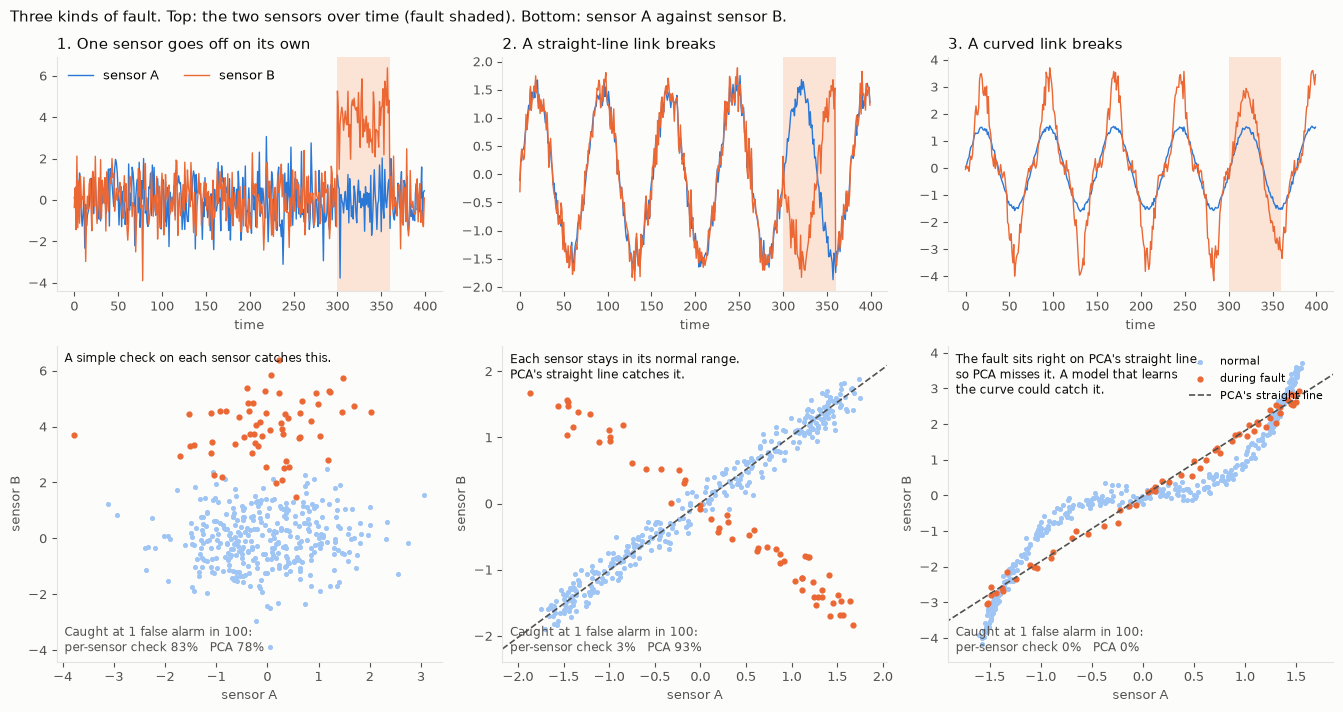

In [2]:
plots.three_kinds_of_fault();

**What we will test, in plain words**

- **H1.** For faults in a single sensor, simple checks are as good as deep learning.
- **H2.** For broken straight-line links, PCA is as good as deep learning.
- **H3.** The more curved or mode-dependent the links, the further ahead deep learning gets.
- **H4.** A data simulator (section 7) can predict which method will win on real data.

Today's work covers the first half: the simple methods on real data. Deep learning comes later.

## 2. Dataset 1: SKAB, a real water pump

**What it is.** A pump pushing water round a loop of pipe, in a lab at Skoltech (Moscow), published in 2020. Researchers ran 34 experiments of about 20 minutes each. In each one they caused one fault on purpose, for example:
- half-closing a valve;
- unbalancing the motor;
- letting air into the pump;
- adding hot water.

**Why we use it.** It's real equipment with real sensor noise. It's small enough for a laptop, and every fault is labelled with its exact start and end.

**The 8 sensors:**

In [3]:
data.SKAB_INFO

,sensor,what it measures,unit
0,Accelerometer1RMS,"Vibration of the pump, sensor 1",g
1,Accelerometer2RMS,"Vibration of the pump, sensor 2",g
2,Current,Electric current drawn by the motor,amps
3,Pressure,Water pressure just after the pump,bar
4,Temperature,Temperature of the motor body,deg C
5,Thermocouple,Temperature of the water in the loop,deg C
6,Voltage,Voltage across the motor,volts
7,Volume Flow RateRMS,How fast water flows round the loop,litres/min


**One experiment, first rows.** Each row is one second. `fault` is 1 while the fault is happening (here it starts later in the file).

In [4]:
df = data.skab_frame("valve1/1")
df.head(8)

,second,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS,fault
0,0,0.02708,0.03961,0.8713,0.05471,75.5,25.83,244.1,32,0
1,1,0.027,0.03876,1.301,0.05471,75.54,25.84,224.2,32,0
2,2,0.02681,0.03952,1.284,0.3826,75.66,25.82,234.2,33,0
3,3,0.02682,0.03863,1.365,0.05471,75.58,25.83,229.9,33,0
4,4,0.02639,0.03877,0.7918,0.05471,75.44,25.84,251.7,32,0
5,5,0.02665,0.03903,0.7502,0.3826,75.55,25.82,246.4,32,0
6,7,0.02636,0.03918,1.264,0.05471,75.56,25.83,252.8,33,0
7,8,0.02643,0.03889,0.6704,0.3826,75.56,25.83,232.3,32,0


**Basic statistics for each sensor** over this experiment: average, spread, smallest and largest reading.

In [5]:
df.drop(columns=["second", "fault"]).describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
Accelerometer1RMS,0.02687,0.0003126,0.02583,0.02795
Accelerometer2RMS,0.04005,0.0009883,0.03761,0.05344
Current,0.979,0.2775,0.3755,1.596
Pressure,0.07447,0.25,-0.9291,1.038
Temperature,73.71,1.333,71,76.28
Thermocouple,25.74,0.0634,25.61,25.92
Voltage,231.4,10.76,203.7,254.5
Volume Flow RateRMS,31.57,0.76,30,33


**The 34 experiments, grouped by kind of fault.** Each detector learns "normal" from the first 400 seconds of an experiment and is tested on the rest. So "% faulty" here is the share of the *tested* part.

In [6]:
skab = data.load("skab")
explore.overview(skab)

,runs,avg minutes per run,avg % faulty
kind of fault,,,
fluid leak or addition,4,10.6,53.8
water level change,2,14.3,60.2
cavitation,2,9.8,49.2
hot water inflow,1,8.4,59.8
rotor imbalance,5,12.3,53.3
inlet valve closed,16,12.2,53.6
outlet valve closed,4,11.3,56.3


**The experiment as a picture.** Each strip is one sensor, and the shaded stretch is the fault: the valve at the pump's inlet is partly closed. Look at the bottom strip: the flow drops while the valve is closed. The other sensors barely react, which is why this kind of fault is hard to spot.

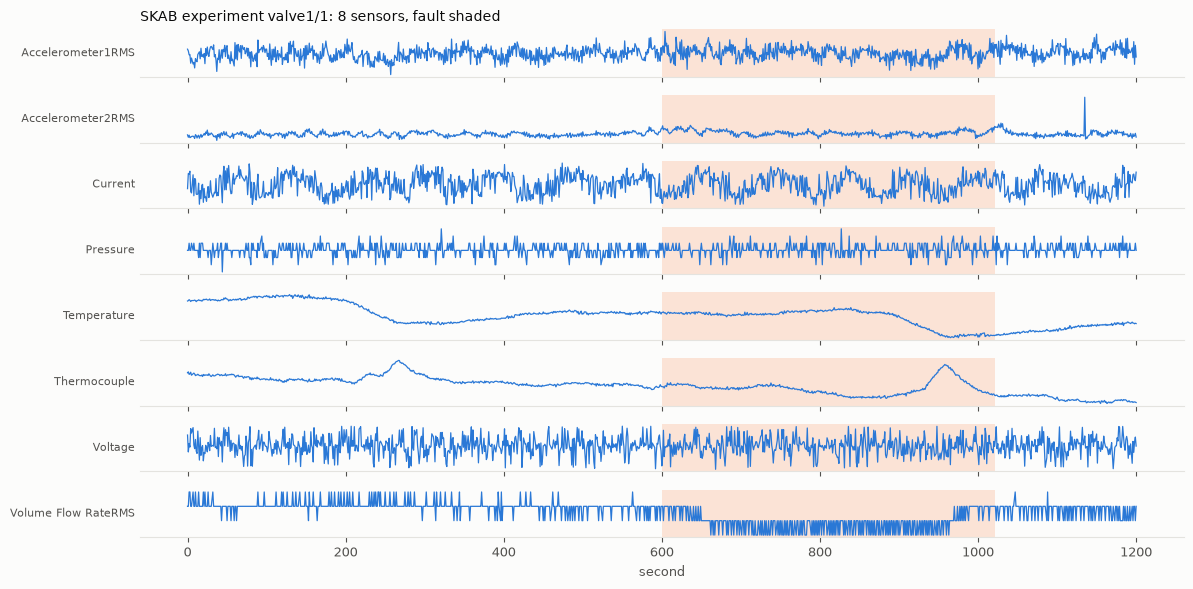

In [7]:
sensors = list(data.SKAB_INFO["sensor"])
plots.stacked(df, sensors, x="second", title="SKAB experiment valve1/1: 8 sensors, fault shaded");

**Which sensors does each kind of fault move?** For each kind of fault, the grid shows how far each sensor moves from its normal level during the fault.
- 1 means it moves by about its usual amount of wiggle; 5 means far more.
- A row with one dark cell is a single-sensor fault. A row with several dark cells moves many sensors at once.

Temperatures also creep slowly during every experiment, which inflates their numbers a little.

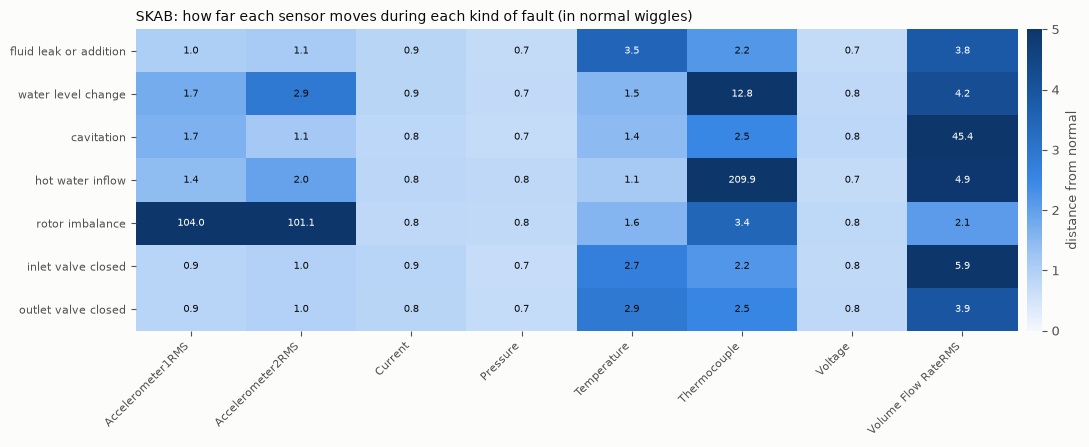

In [8]:
plots.heatmap(explore.fingerprint(skab), vmax=5,
              title="SKAB: how far each sensor moves during each kind of fault (in normal wiggles)",
              colorbar_label="distance from normal");

**Which sensors normally move together?** This is the correlation between each pair of sensors over the 2.5-hour fault-free recording.
- +1 means two sensors rise and fall together; −1 means one rises when the other falls; 0 means no straight-line link.
- Strong links are what PCA relies on.

On this rig two groups stand out:
- Vibration, the two temperatures and the flow all move together strongly. Part of that is the whole rig slowly warming up during the recording.
- Current moves with voltage.

Pressure isn't linked to anything.

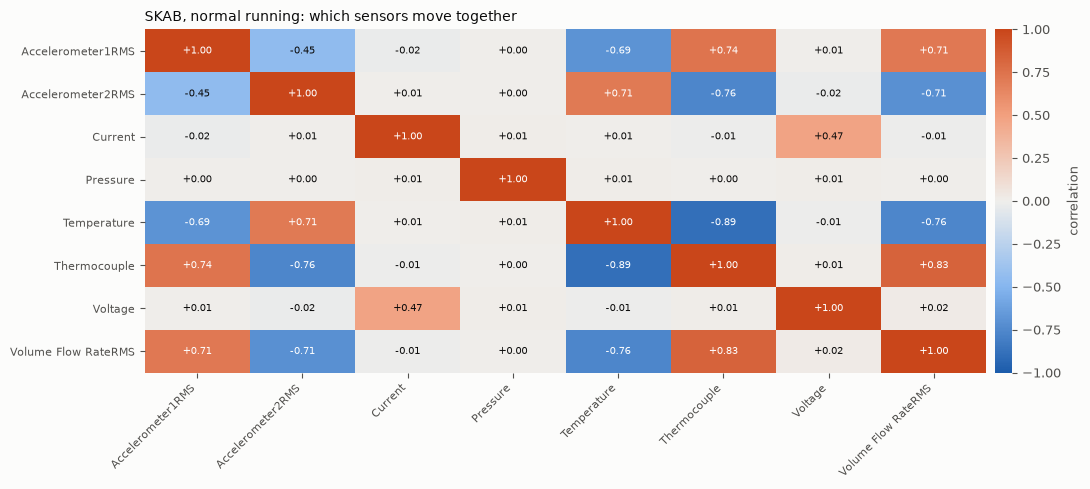

In [9]:
normal = data.skab_frame("anomaly-free/anomaly-free")
plots.heatmap(explore.correlations(normal[sensors].values, sensors), vmax=1, diverging=True, fmt="{:+.2f}",
              title="SKAB, normal running: which sensors move together", colorbar_label="correlation");

## 3. Dataset 2: Tennessee Eastman, a simulated chemical plant

**What it is.** A computer model of a real chemical plant, published by the Eastman Chemical Company in 1993 as a shared test problem.
- **Equipment:** a reactor, a condenser, a compressor, a separator and a stripper, with control systems keeping them steady.
- **Our copy:** the files generated by Richard Braatz's lab at the University of Illinois.
- **Each test run:** 48 simulated hours with one reading every 3 minutes. A fault switches on after 8 hours.
- **Faults:** 21 programmed kinds.

**Why we use it.** Its 52 measurements are tightly linked by physics and control loops, so faults often show up as broken links rather than odd single readings. It's also where PCA has been the standard tool for decades, so it's the fair place to ask whether deep learning can beat PCA.

**The 52 variables come in three kinds:**

In [10]:
data.TEP_INFO.groupby("kind").size().rename("how many").to_frame()

,how many
kind,
"lab analysis, updates every 6-15 min",19
"sensor reading, every 3 min",22
valve / controller setting,11


In [11]:
data.TEP_INFO

,variable,what it measures,unit,kind
0,XMEAS(1),A feed (stream 1),kscmh,"sensor reading, every 3 min"
1,XMEAS(2),D feed (stream 2),kg/h,"sensor reading, every 3 min"
2,XMEAS(3),E feed (stream 3),kg/h,"sensor reading, every 3 min"
3,XMEAS(4),A and C feed (stream 4),kscmh,"sensor reading, every 3 min"
4,XMEAS(5),Recycle flow,kscmh,"sensor reading, every 3 min"
5,XMEAS(6),Reactor feed rate,kscmh,"sensor reading, every 3 min"
6,XMEAS(7),Reactor pressure,kPa,"sensor reading, every 3 min"
7,XMEAS(8),Reactor level,%,"sensor reading, every 3 min"
8,XMEAS(9),Reactor temperature,deg C,"sensor reading, every 3 min"
9,XMEAS(10),Purge rate,kscmh,"sensor reading, every 3 min"


**Fault 1 around the moment it switches on** (8 hours = row 160). First 10 variables only.

In [12]:
tep_df = data.tep_frame(1)
tep_df.loc[156:165, ["hour"] + data.TEP_CHANNELS[:10] + ["fault"]]

,hour,XMEAS(1),XMEAS(2),XMEAS(3),XMEAS(4),XMEAS(5),XMEAS(6),XMEAS(7),XMEAS(8),XMEAS(9),XMEAS(10),fault
156,7.8,0.2202,3672,4518,9.287,26.91,42.2,2708,76.27,120.4,0.3318,0
157,7.85,0.2208,3637,4560,9.485,26.74,42.39,2708,74.88,120.4,0.3332,0
158,7.9,0.1848,3636,4524,9.309,26.93,42.28,2709,74.77,120.4,0.3575,0
159,7.95,0.1852,3622,4538,9.334,26.98,42.04,2707,75.27,120.4,0.3554,0
160,8,0.2068,3613,4456,9.29,26.82,42.12,2710,75.14,120.4,0.3423,1
161,8.05,0.2086,3621,4554,9.475,26.54,42.07,2715,75.25,120.4,0.3429,1
162,8.1,0.2295,3678,4555,9.397,26.82,42.01,2720,75.19,120.4,0.3239,1
163,8.15,0.2276,3672,4514,9.343,27.13,42.44,2722,75.49,120.4,0.3226,1
164,8.2,0.2283,3654,4577,9.24,27.05,42.2,2723,75.67,120.4,0.338,1
165,8.25,0.2308,3676,4520,9.35,27.09,42.39,2724,75.29,120.4,0.3383,1


**The 21 faults.** Detectors learn "normal" from a separate fault-free run, then are tested on each fault run. The first 8 hours of each run are normal, so 83% of each run is faulty.

In [13]:
tep = data.load("tep")
explore.overview(tep)

,runs,avg minutes per run,avg % faulty
kind of fault,,,
01 step: A/C feed ratio,1,2880,83.3
02 step: B composition,1,2880,83.3
03 step: D feed temperature,1,2880,83.3
04 step: reactor cooling water temp,1,2880,83.3
05 step: condenser cooling water temp,1,2880,83.3
06 step: A feed loss,1,2880,83.3
07 step: C header pressure loss,1,2880,83.3
"08 random: A, B, C feed composition",1,2880,83.3
09 random: D feed temperature,1,2880,83.3


**Fault 1 as a picture, four variables.** The fault changes the mix of two ingredients fed in (A and C).
- The A feed and the valve that controls it swing, then settle at new levels.
- Reactor temperature doesn't move at all, because a controller holds it steady.

That's typical of this plant: control systems hide a fault in one place and push it somewhere else.

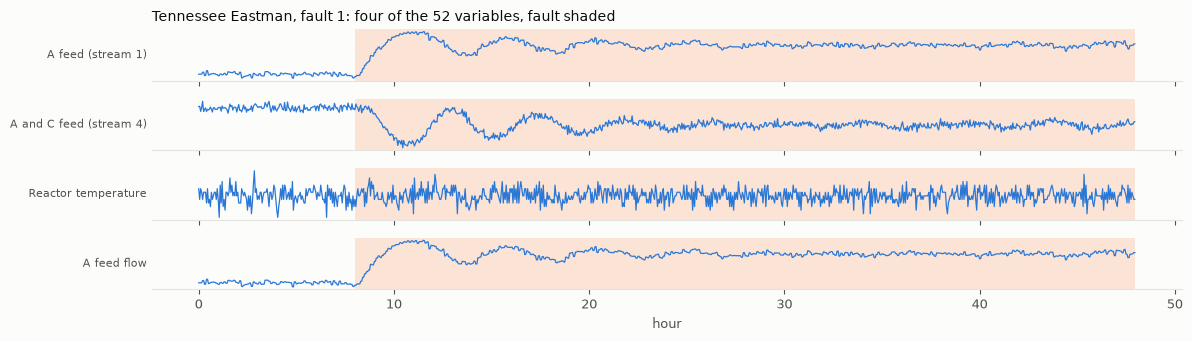

In [14]:
labels = dict(zip(data.TEP_INFO["variable"], data.TEP_INFO["what it measures"]))
plots.stacked(tep_df, ["XMEAS(1)", "XMEAS(4)", "XMEAS(9)", "XMV(3)"], x="hour",
              title="Tennessee Eastman, fault 1: four of the 52 variables, fault shaded", labels=labels);

**All 52 variables at once.** Each row is one variable, and the colour shows how far it is from its normal level: blue is below, orange is above, pale is normal. After the dashed line, fault 1 lights up many rows.

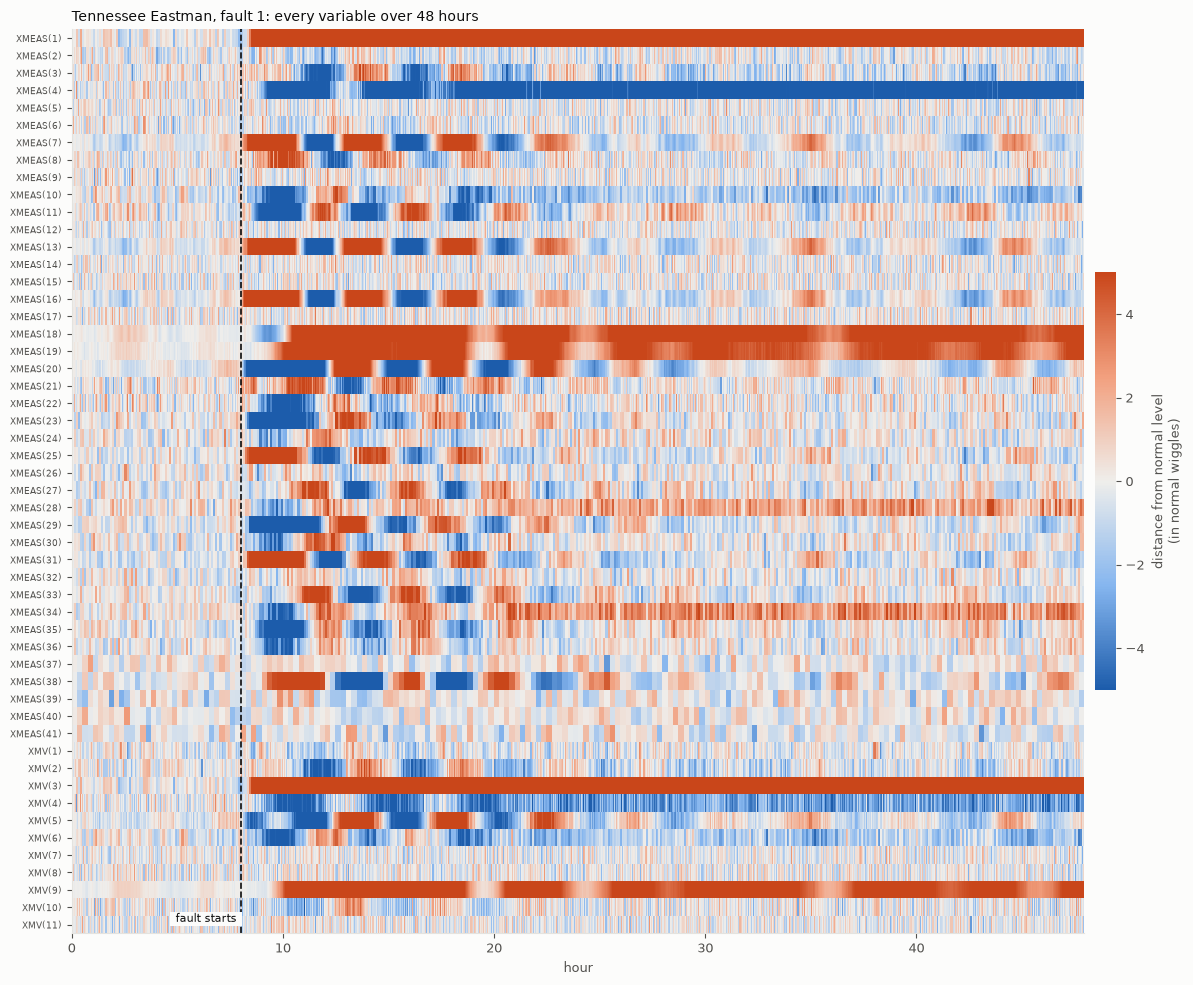

In [15]:
plots.all_sensors_over_time(tep_df, tep.runs[0].fit, data.TEP_CHANNELS, "hour", onset=8,
                            title="Tennessee Eastman, fault 1: every variable over 48 hours");

**A hard fault, for comparison.** Fault 15 is a sticking valve in the condenser's cooling water, and it barely shows at all. It's widely treated as undetectable.

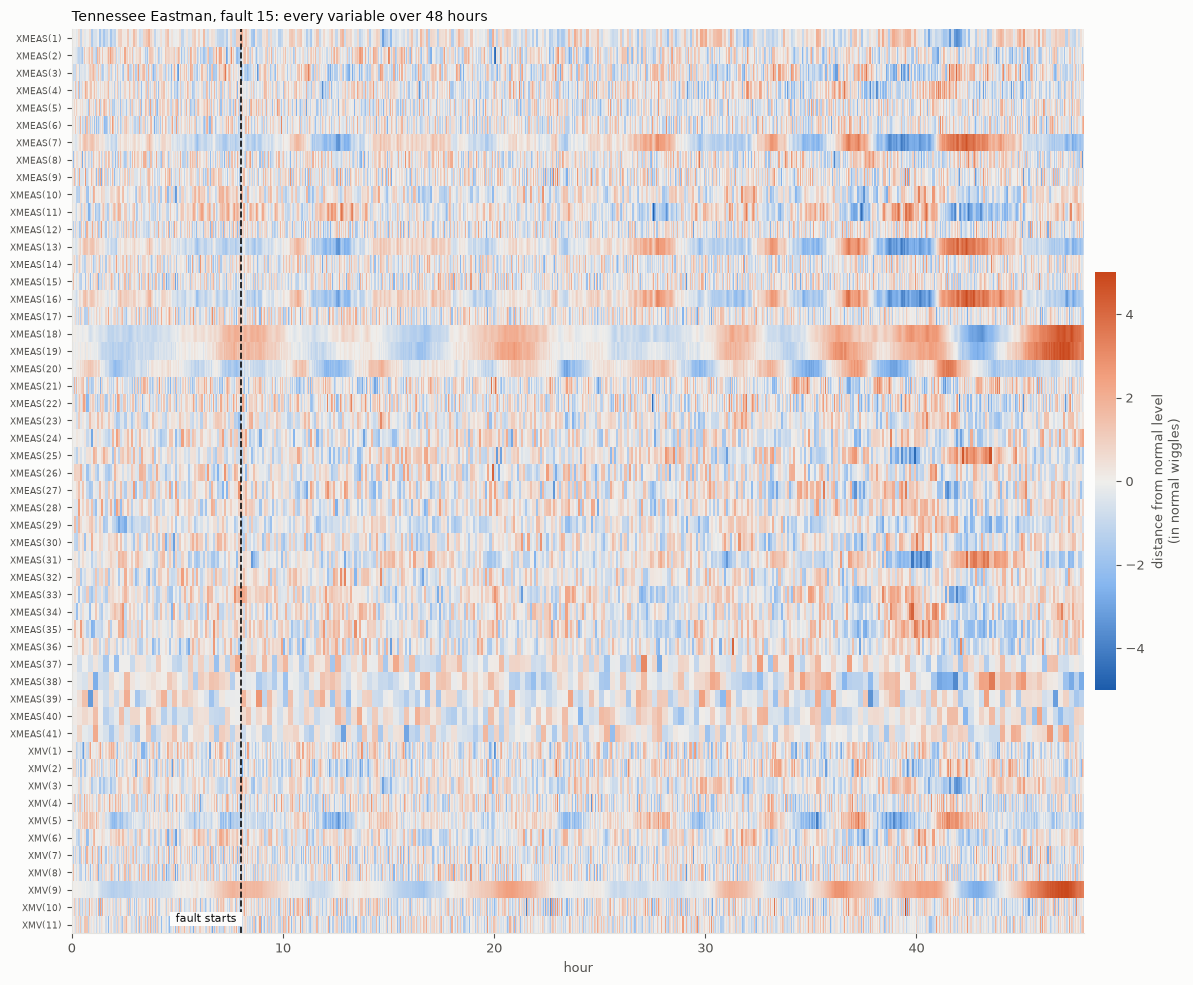

In [16]:
plots.all_sensors_over_time(data.tep_frame(15), tep.runs[0].fit, data.TEP_CHANNELS, "hour", onset=8,
                            title="Tennessee Eastman, fault 15: every variable over 48 hours");

**Fingerprint of all 21 faults.** This is the same idea as for SKAB: how far each variable moves during each fault.
- Faults 3, 9 and 15 are almost blank rows.
- Some faults, such as fault 4, move only one or two variables strongly. That's easy for a per-sensor check.
- Others move dozens of variables at once.

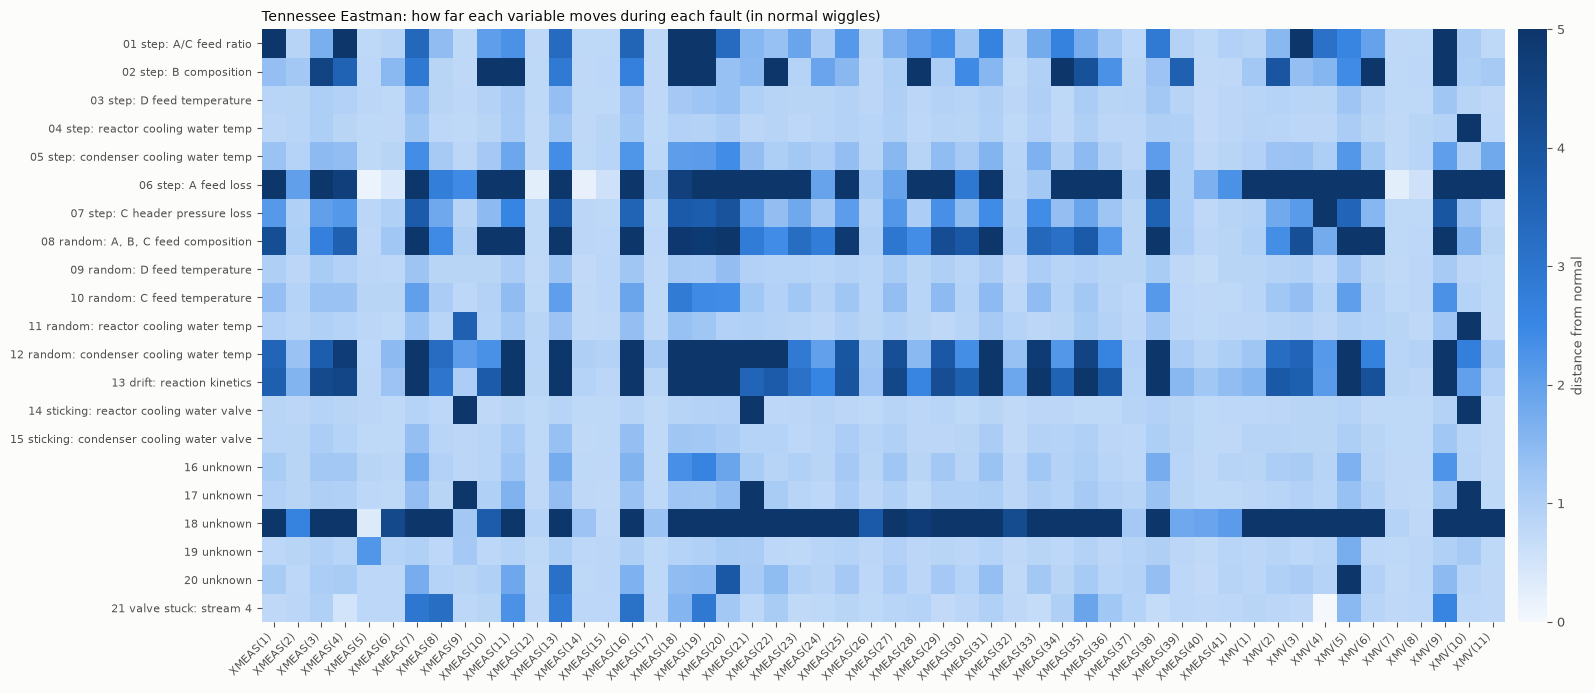

In [17]:
plots.heatmap(explore.fingerprint(tep), vmax=5, annotate=False, figsize=(16, 7),
              title="Tennessee Eastman: how far each variable moves during each fault (in normal wiggles)",
              colorbar_label="distance from normal");

**Which variables normally move together?** There are many strong links (dark squares), which is what makes this plant a good test for PCA.

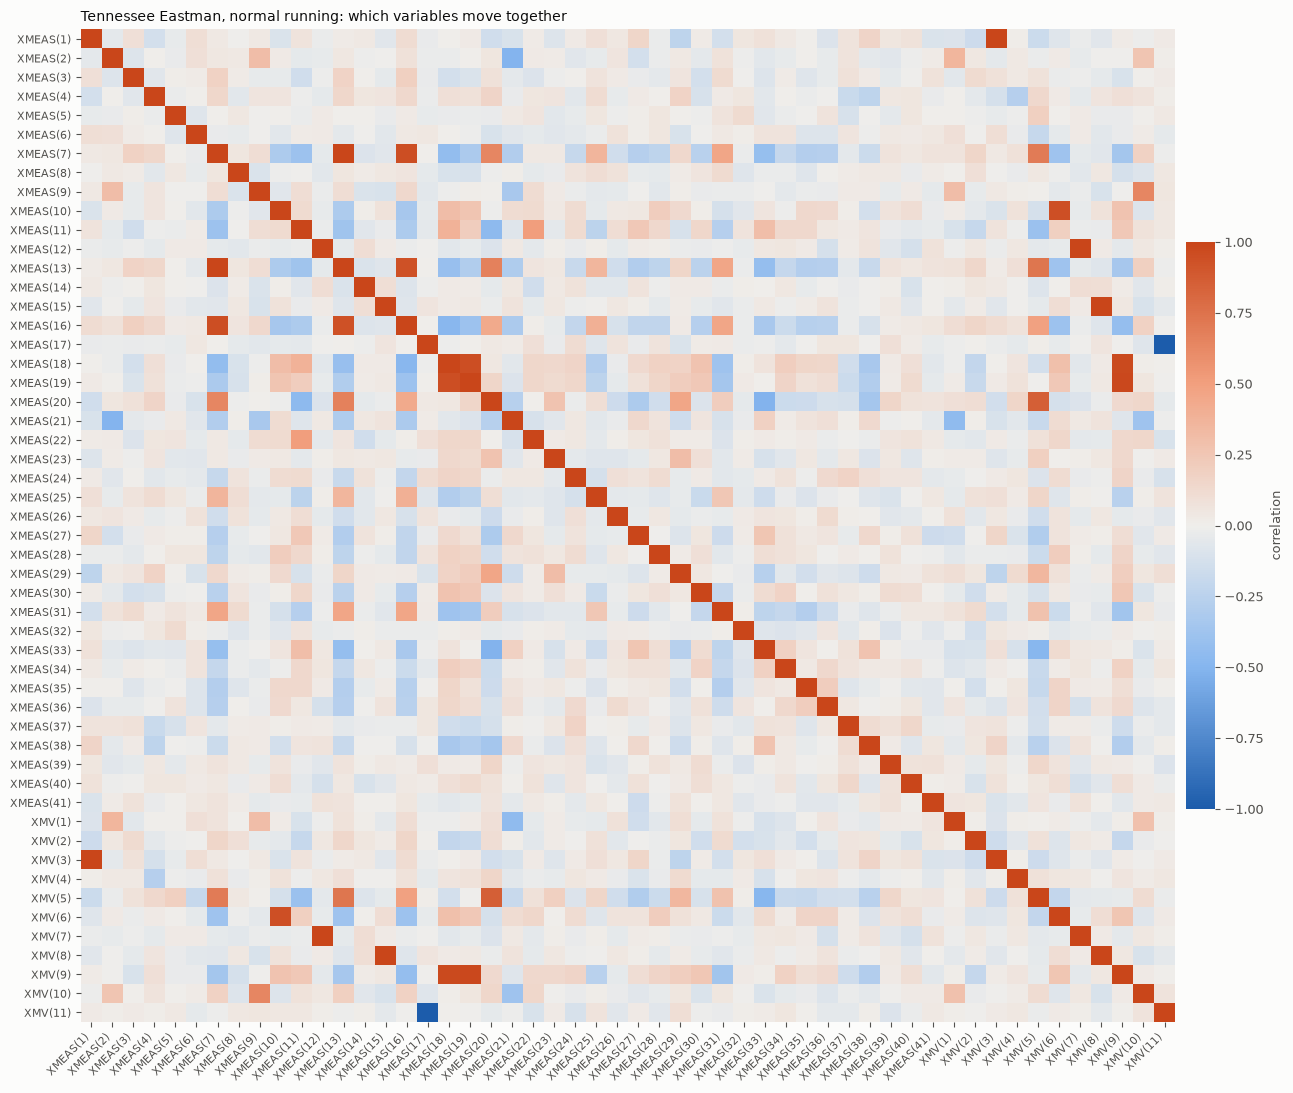

In [18]:
fit = tep.runs[0].fit
plots.heatmap(explore.correlations(fit, data.TEP_CHANNELS), vmax=1, diverging=True, annotate=False,
              figsize=(13, 11), title="Tennessee Eastman, normal running: which variables move together",
              colorbar_label="correlation");

## 4. How a detector is judged

Every detector gives each moment a **weirdness score**. To turn scores into alarms you draw a line: anything above the line is an alarm.

Where to draw that line is a trade-off:
- **A low line** catches more of the fault, but also rings when nothing is wrong.
- **A high line** gives few false alarms, but misses more of the fault.

To compare detectors fairly, every detector gets **the same false-alarm budget: 1 per 100 normal moments**. Each detector's line is placed to use exactly that budget, and then we count what share of the fault moments it catches.

Think of testing smoke detectors: tune each one so it goes off by mistake equally often, then see which catches the most real smoke.

**Which normal moments set the line?** The alarm line is set on healthy readings from the same time window that the faults occupy. In the chemical plant the faults start 8 hours into a run, so each detector's line is set on hours 8 to 48 of a fault-free run. This matters because a healthy plant drifts slowly: an alarm line set only on the first hours of a run ends up too low for the rest of it, and the per-sensor charts then ring all the time. `03_fresh_runs.ipynb` measures how much that inflated the earlier numbers. SKAB doesn't need this change, because each experiment's alarm line already uses normal readings from before and after its fault.

We use this instead of *accuracy* because accuracy is easily fooled. If faults are rare, a detector that never rings is "99% accurate".

The pictures show the rule for the simplest detector (the rolling z-score from section 5) on two SKAB experiments. First an easy fault: the motor is unbalanced and vibration jumps.

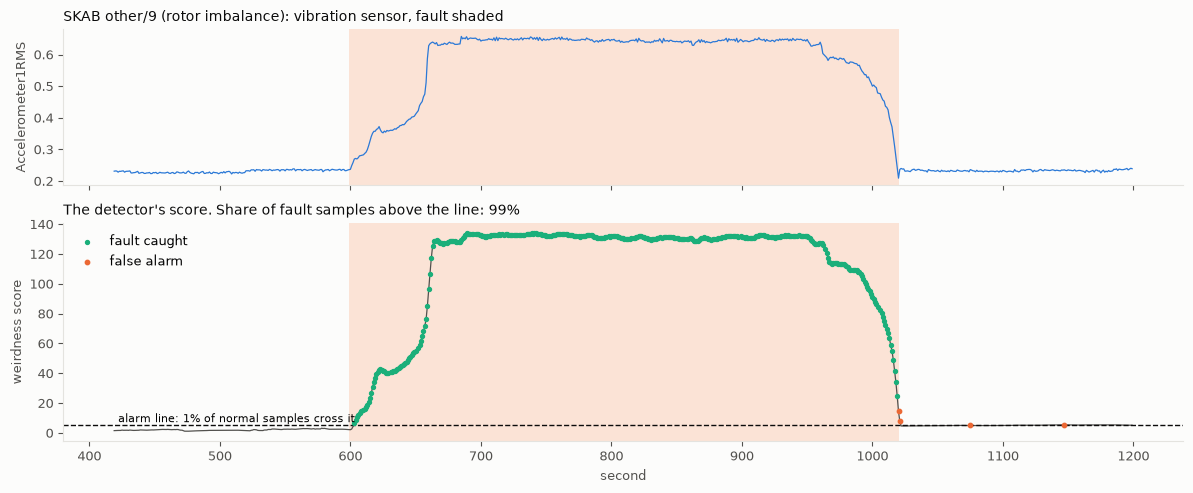

In [19]:
def score_one(experiment, method="rolling_z", **settings):
    r = next(x for x in skab.runs if x.name == experiment)
    detector = detectors.make(method, **settings).fit(r.fit)   # learn "normal" from the first 400 seconds
    tested = data.skab_frame(experiment).iloc[len(r.fit):].reset_index(drop=True)
    return tested, detector.score(r.X)                         # weirdness score for the tested part


tested, score = score_one("other/9", window=5)
plots.how_scoring_works(tested, "Accelerometer1RMS", score, x="second",
                        title="SKAB other/9 (rotor imbalance): vibration sensor, fault shaded");

**Now a hard one: the valve experiment from section 2.**

The fault here is small: the flow drops by about one unit. Meanwhile the rig keeps warming up, so the temperature sensors drift further from their opening values. The weirdness score creeps up through the whole run, highest of all after the fault ends. To keep false alarms at 1 in 100, the alarm line has to sit above the fault, and this detector catches none of it.

Slow drift that isn't a fault is one of the main reasons real-world detection is hard.

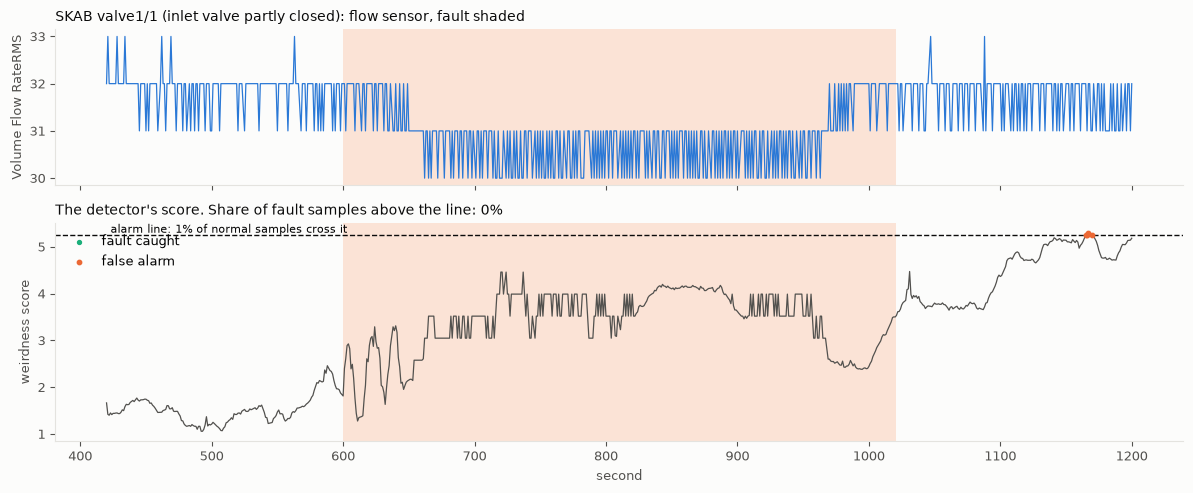

In [20]:
tested, score = score_one("valve1/1", window=5)
plots.how_scoring_works(tested, "Volume Flow RateRMS", score, x="second",
                        title="SKAB valve1/1 (inlet valve partly closed): flow sensor, fault shaded");

## 5. The simple detectors, on both datasets

These are the eight simple methods any deep model has to beat:

| Detector | The idea in one line |
|---|---|
| Rolling z-score | Is any one sensor far from its normal average over the last few readings? |
| EWMA chart | The same, with a smoothed running average, so it reacts to small steady shifts |
| CUSUM chart | Adds up small deviations over time, so it catches slow creeps |
| PCA (T² + SPE) | Learns the straight-line links between sensors and flags readings that break them |
| Isolation Forest | A machine-learning method that flags readings that are easy to separate from the rest |
| Matrix Profile | Compares each short stretch of readings with the most similar stretch of normal data |
| Straight-link residual | Predicts each sensor from all the other sensors using straight-line links, and flags readings that are far from the prediction |
| Curved-link residual | The same, with a flexible model added so the prediction can also follow curved links |

A *residual* is the gap between a reading and what was predicted for it. The last two detectors were added after the first six; `02_how_curved.ipynb` explains where they come from.

Their current settings:

In [21]:
pd.Series(run.METHODS, name='settings').to_frame()

,settings
rolling_z,{'window': 5}
ewma,{'lam': 0.2}
cusum,{'k': 0.5}
pca,{'var': 0.9}
iforest,"{'window': 10, 'n_estimators': 100}"
matrix_profile,{'m': 16}
link_straight,{'window': 5}
link_curved,{'window': 5}


**Score everything.** The first time takes about ten minutes, most of it for the two link-residual detectors. After that, results come from `results/cache/` instantly. Then we work out each detector's catch rate, and how much of that number could be luck.

In [22]:
run.score_all(verbose=False)
results = {name: run.report_dataset(data.load(name), list(run.METHODS), n_seeds=5, n_boot=1000)
           for name in ["skab", "tep"]}


def simple_table(res):
    t = pd.DataFrame(res["summary"]).sort_values("dr_at_1pct", ascending=False)
    pct = lambda v: (100 * v).round(0).astype(int).astype(str) + "%"
    out = pd.DataFrame({
        "detector": t["method"],
        "fault caught (1 false alarm in 100)": pct(t["dr_at_1pct"]),
        "plausible range": [f"{100 * a:.0f}-{100 * b:.0f}%" for a, b in zip(t["dr_ci90_low"], t["dr_ci90_high"])],
    })
    if "dr_old_rule" in t:    # chemical plant only: the catch rate under the earlier alarm-line rule
        out["old rule (first 8 hours)"] = pct(t["dr_old_rule"])
    out["faults flagged at all (real-world threshold)"] = pct(t["deploy_events_flagged"])
    return out.set_index("detector")


print("SKAB (water pump)")
display(simple_table(results["skab"]))
print("Tennessee Eastman (chemical plant)")
display(simple_table(results["tep"]))

SKAB (water pump)


,fault caught (1 false alarm in 100),plausible range,faults flagged at all (real-world threshold)
detector,,,
Straight-link residual,64%,55-73%,41%
Curved-link residual,61%,51-70%,44%
Matrix Profile,56%,44-67%,26%
Rolling z-score,50%,38-60%,26%
EWMA chart,50%,38-60%,26%
PCA (T2 + SPE),41%,30-51%,26%
Isolation Forest,24%,18-33%,48%
CUSUM chart,8%,2-16%,3%


Tennessee Eastman (chemical plant)


,fault caught (1 false alarm in 100),plausible range,old rule (first 8 hours),faults flagged at all (real-world threshold)
detector,,,,
Straight-link residual,81%,68-92%,81%,100%
Curved-link residual,81%,68-92%,81%,100%
Matrix Profile,72%,60-84%,76%,100%
CUSUM chart,70%,56-82%,71%,86%
PCA (T2 + SPE),64%,50-78%,65%,100%
Rolling z-score,60%,46-74%,62%,100%
EWMA chart,59%,45-74%,61%,95%
Isolation Forest,40%,28-56%,41%,100%


**How to read the "plausible range".** With only 34 SKAB experiments and 21 plant faults, every number has some luck in it. The range shows where the number could reasonably land with a different set of experiments. Where two detectors' ranges overlap a lot, we can't call one better.

**"Faults flagged at all"** uses a line set the way you would in real life, without peeking at the test run. On SKAB it falls apart: each experiment's sensors drift differently, so a line set on other experiments doesn't fit the new one.

**"Old rule (first 8 hours)"**, in the plant table only, is the catch rate under the earlier way of setting the alarm line (section 4). Where it is higher than the first column, the earlier number was inflated. The plant's new alarm lines rest on a single fault-free run, because these files have only one.

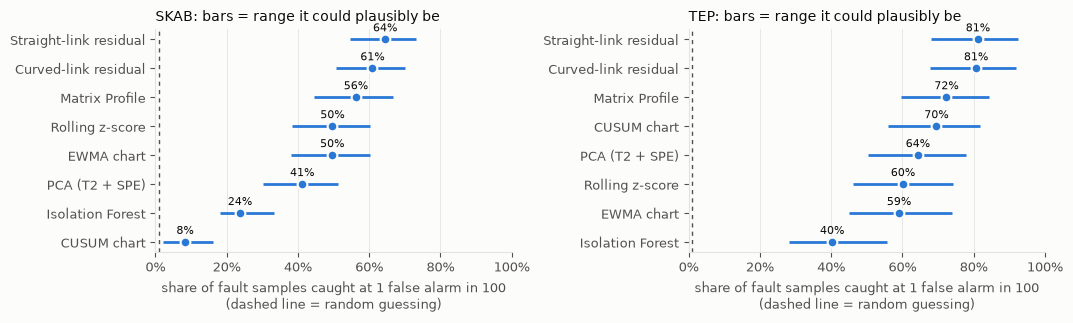

In [23]:
plots.pilot_overall(results);

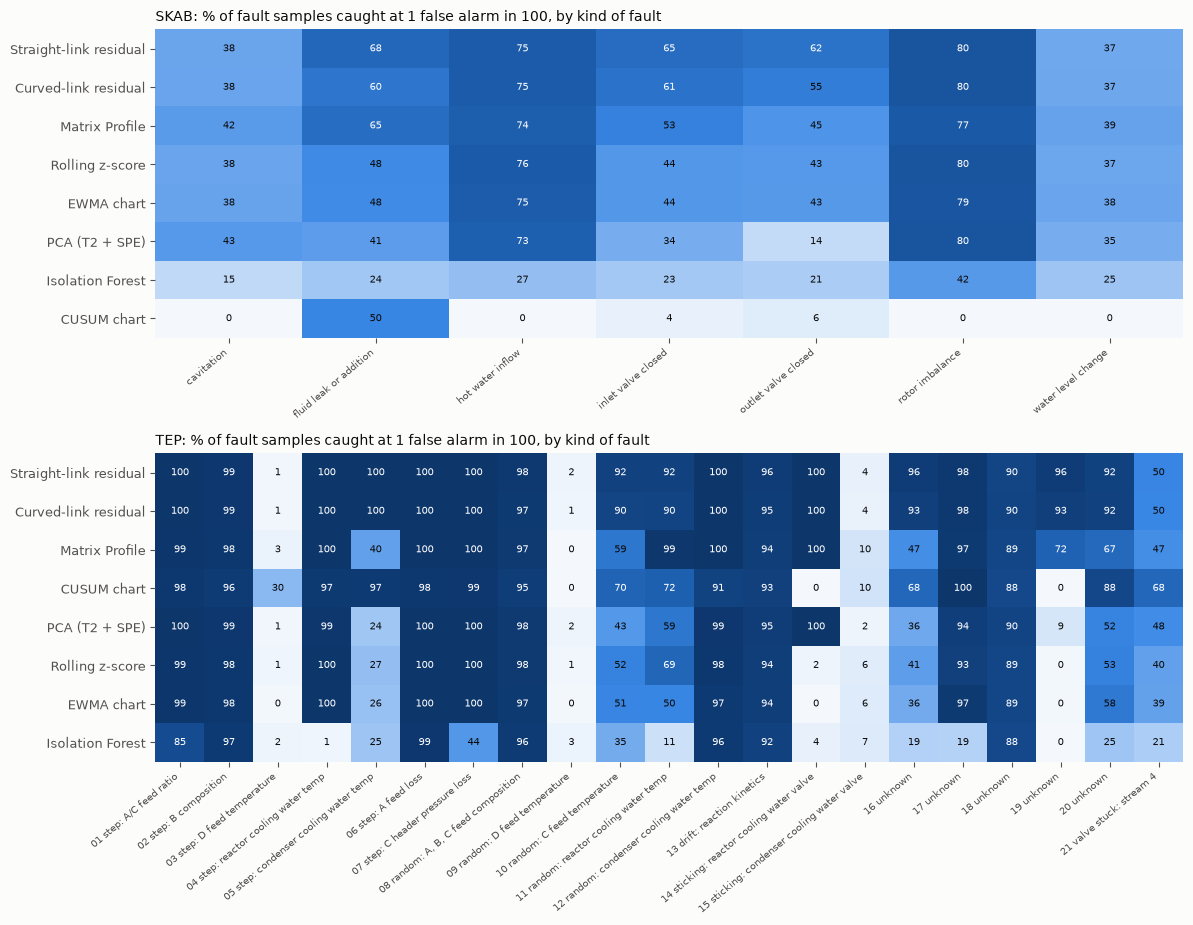

In [24]:
plots.pilot_by_type(results);

**What this tells us so far**
- **Two detectors tie for best: the straight-link residual detector and Matrix Profile.** The straight-link detector is ahead on both datasets: 64% against 56% on SKAB, and 81% against 72% in the plant. But both gaps (8 and 9 points) are under 12 points, which is too small to call a winner (see the rule below). Together these two are the bar deep learning has to beat.
- **Real wins for the straight-link detector.** On both datasets it beats PCA, the rolling z-score, the EWMA chart and Isolation Forest by 12 points or more. On SKAB it also beats the CUSUM chart.
- **Ties for the straight-link detector.** Matrix Profile and the curved-link detector on both datasets. In the plant also the CUSUM chart, where the gap is just under 12 points.
- **Real wins for Matrix Profile.** Isolation Forest on both datasets; PCA and the CUSUM chart on SKAB; the rolling z-score and the EWMA chart in the plant. It ties with the rest.
- **PCA is clearly behind the straight-link detector**, by 23 points on SKAB and 17 in the plant.
- **Curves add nothing here.** The curved-link detector catches the same 81% as the straight-link one in the plant, and slightly less on SKAB (61%).
- **The old rule flattered some detectors in the plant.** Matrix Profile reads 4 points lower under the new rule and the per-sensor charts about 2 points lower. The link-residual detectors and PCA barely move. On 1,000 fresh runs the effect is larger for the per-sensor charts: they lose 5 to 9 points (`03_fresh_runs.ipynb`).
- **Some faults are hard for everyone.** On SKAB, no detector catches even half of the cavitation or water-level faults. In the plant, faults 3, 9 and 15 are nearly invisible. The CUSUM chart seems to catch 30% of fault 3 here, but on 50 fresh runs of that fault it catches nothing: this one run was lucky.
- **Small differences could be luck.** We only call one detector better than another if it catches at least **12 more fault moments in 100**, and the gap's plausible range stays clear of zero. So deep learning has to beat the bar by at least 12 points to count as a real win.

**Checked on fresh runs.** The settings of the two link-residual detectors were chosen after looking at these same test runs. For the plant, `03_fresh_runs.ipynb` has since confirmed the result on 1,000 runs the detectors had never seen: 83% there, against 83% here for the same 20 faults. For SKAB there are no fresh runs, so its 64% is still optimistic.

**The verdicts, pair by pair.** For each dataset, the first table compares every detector with every other: *ahead* means the detector in the row beats the one in the column by at least 0.12 with a plausible range clear of zero, *behind* is the reverse, and anything else is a *tie*. The next two tables give the gaps themselves for the two best detectors. A positive gap means the detector named in the table's corner catches more; *low* and *high* are the gap's plausible range.

In [25]:
for name, res in results.items():
    print(name)
    display(run.verdict_table(res))
    display(run.gap_table(res, "Straight-link residual").round(3))
    display(run.gap_table(res, "Matrix Profile").round(3))

skab


,Straight-link residual,Curved-link residual,Matrix Profile,Rolling z-score,EWMA chart,PCA (T2 + SPE),Isolation Forest,CUSUM chart
row against column,,,,,,,,
Straight-link residual,,tie,tie,ahead,ahead,ahead,ahead,ahead
Curved-link residual,tie,,tie,tie,tie,ahead,ahead,ahead
Matrix Profile,tie,tie,,tie,tie,ahead,ahead,ahead
Rolling z-score,behind,tie,tie,,tie,tie,ahead,ahead
EWMA chart,behind,tie,tie,tie,,tie,ahead,ahead
PCA (T2 + SPE),behind,behind,behind,tie,tie,,ahead,ahead
Isolation Forest,behind,behind,behind,behind,behind,behind,,ahead
CUSUM chart,behind,behind,behind,behind,behind,behind,behind,


,gap,low,high,verdict
Straight-link residual against,,,,
Rolling z-score,0.148,0.077,0.221,ahead
EWMA chart,0.148,0.077,0.226,ahead
CUSUM chart,0.562,0.454,0.663,ahead
PCA (T2 + SPE),0.233,0.147,0.316,ahead
Isolation Forest,0.387,0.284,0.473,ahead
Matrix Profile,0.082,0.029,0.141,tie
Curved-link residual,0.036,0.01,0.064,tie


,gap,low,high,verdict
Matrix Profile against,,,,
Rolling z-score,0.066,0.023,0.121,tie
EWMA chart,0.066,0.021,0.126,tie
CUSUM chart,0.48,0.364,0.588,ahead
PCA (T2 + SPE),0.151,0.078,0.227,ahead
Isolation Forest,0.305,0.186,0.405,ahead
Straight-link residual,-0.082,-0.141,-0.029,tie
Curved-link residual,-0.046,-0.094,-0.004,tie


tep


,Straight-link residual,Curved-link residual,Matrix Profile,CUSUM chart,PCA (T2 + SPE),Rolling z-score,EWMA chart,Isolation Forest
row against column,,,,,,,,
Straight-link residual,,tie,tie,tie,ahead,ahead,ahead,ahead
Curved-link residual,tie,,tie,tie,ahead,ahead,ahead,ahead
Matrix Profile,tie,tie,,tie,tie,ahead,ahead,ahead
CUSUM chart,tie,tie,tie,,tie,tie,tie,ahead
PCA (T2 + SPE),behind,behind,tie,tie,,tie,tie,ahead
Rolling z-score,behind,behind,behind,tie,tie,,tie,ahead
EWMA chart,behind,behind,behind,tie,tie,tie,,ahead
Isolation Forest,behind,behind,behind,behind,behind,behind,behind,


,gap,low,high,verdict
Straight-link residual against,,,,
Rolling z-score,0.21,0.101,0.335,ahead
EWMA chart,0.221,0.108,0.353,ahead
CUSUM chart,0.116,0.018,0.235,tie
PCA (T2 + SPE),0.169,0.069,0.268,ahead
Isolation Forest,0.398,0.265,0.543,ahead
Matrix Profile,0.088,0.029,0.158,tie
Curved-link residual,0.005,0.002,0.009,tie


,gap,low,high,verdict
Matrix Profile against,,,,
Rolling z-score,0.122,0.041,0.219,ahead
EWMA chart,0.133,0.046,0.234,ahead
CUSUM chart,0.028,-0.081,0.15,tie
PCA (T2 + SPE),0.08,0.028,0.139,tie
Isolation Forest,0.31,0.189,0.435,ahead
Straight-link residual,-0.088,-0.158,-0.029,tie
Curved-link residual,-0.083,-0.152,-0.025,tie


**Where the 12 comes from.** A gap between two detectors wobbles by chance, depending on which experiments happen to be in the test. In the first version of this comparison, with six detectors, twice the typical wobble came to about 12 points on both datasets. The margin has been fixed at 12 points since then, so it doesn't shift when detectors are added. The table shows the wobble measured now, for information.

In [26]:
pd.DataFrame({name: res["noise"] for name, res in results.items()}).T.rename(columns={
    "median_pair_sd": "typical wobble in a gap", "max_pair_sd": "largest wobble", "margin": "fixed margin to call a win"})

,typical wobble in a gap,largest wobble,fixed margin to call a win
skab,0.04897,0.06845,0.12
tep,0.06153,0.08593,0.12


## 6. Playground

Change things here and rerun the cell. Three things to try:

**a) Look at any experiment or fault.** SKAB experiment names are listed by `data.skab_experiments()`. Plant faults are numbered 1-21 (0 is the normal run).

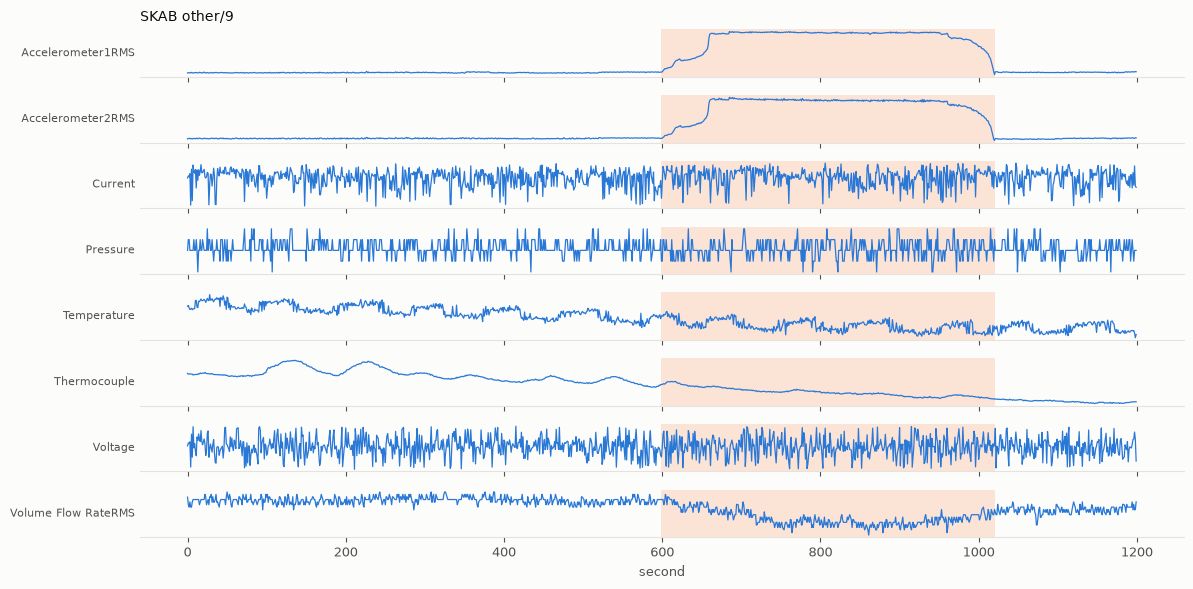

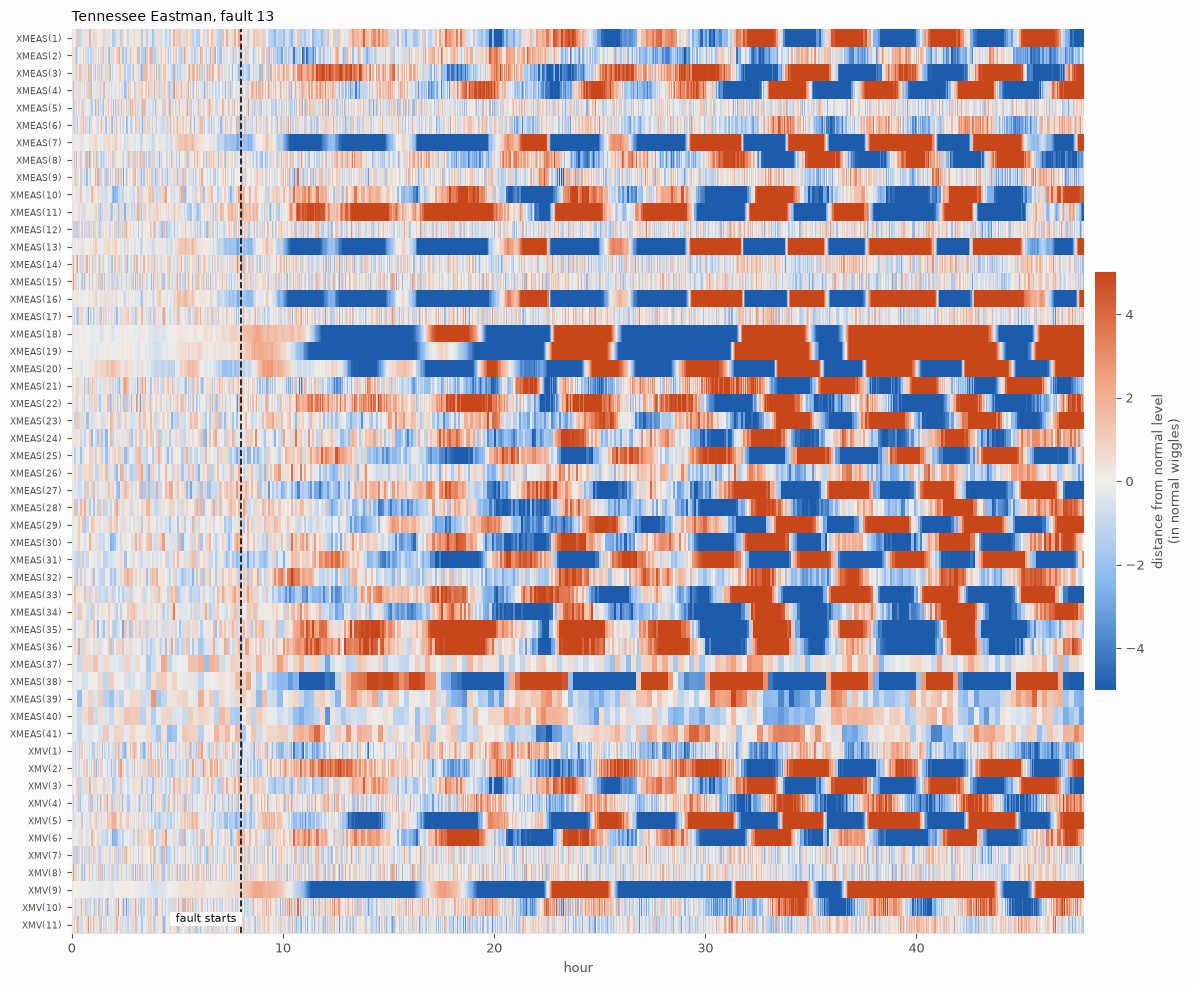

In [27]:
SKAB_EXPERIMENT = "other/9"   # e.g. "valve2/0", "other/13"
TEP_FAULT = 13                # 1-21

plots.stacked(data.skab_frame(SKAB_EXPERIMENT), sensors, x="second", title=f"SKAB {SKAB_EXPERIMENT}")
plots.all_sensors_over_time(data.tep_frame(TEP_FAULT), tep.runs[0].fit, data.TEP_CHANNELS, "hour", onset=8,
                            title=f"Tennessee Eastman, fault {TEP_FAULT}");

**b) Change a detector's settings and see what happens.** Each setting change gets its own cache file, so nothing old is overwritten.
- PCA's `var` is how much of the normal variation its straight lines must explain. Higher means more lines.
- `window` for the rolling z-score is how many readings it averages.

In [28]:
run.METHODS["pca"] = {"var": 0.95}            # try 0.80, 0.95, 0.99
run.score_all(methods=["pca"], verbose=False)
trial = run.report_dataset(data.load("tep"), ["pca", "matrix_profile"], n_seeds=1, n_boot=300)
display(simple_table(trial))
run.METHODS["pca"] = {"var": 0.90}            # back to the default

,fault caught (1 false alarm in 100),plausible range,old rule (first 8 hours),faults flagged at all (real-world threshold)
detector,,,,
Matrix Profile,72%,60-85%,76%,100%
PCA (T2 + SPE),64%,51-77%,67%,100%


**c) Try your own detector.** Write a `score` method that returns one weirdness number per moment. `self._z(X)` gives every sensor in units of its normal wiggle. The example below averages the weirdness across sensors, instead of taking the largest like the rolling z-score does.

In [29]:
class AverageWeirdness(detectors.Detector):
    name = "Average weirdness"

    def score(self, X):
        Z = self._z(X)               # rows = moments, columns = sensors, in normal wiggles
        return np.abs(Z).mean(axis=1)


for name in ["skab", "tep"]:
    out = run.quick_score(data.load(name), AverageWeirdness)
    print(f"{name}: caught {out['caught']:.0%} of fault moments at 1 false alarm in 100")

skab: caught 39% of fault moments at 1 false alarm in 100


tep: caught 49% of fault moments at 1 false alarm in 100


## 7. What's next: why generate data when we already have two datasets?

The two public datasets are our **real-world check**, and we keep using them. But on their own they can't answer the main question:

- **Too few examples.** There are 34 experiments and 21 faults. With so few, only big differences between methods stand out from luck.
- **We can't turn the knobs.** To test H3 we need to make the links between sensors gradually more curved and watch where PCA starts failing. Real datasets are fixed: we can't make the pump "a bit more curved".

So the next step is a **simulator**: a program that makes artificial sensor data.
- We choose how the sensors are linked: straight, curved, or depending on the machine's mode.
- We plant faults of each kind at a strength we choose, and as many as we like.

It's like a wind tunnel. Designs are tested under controlled conditions, then confirmed on real flights, which here are our two datasets. The toy example in section 1 is a tiny version of this.

**Plan**
1. ✅ Write down the question and the tests.
2. ✅ Run the simple detectors on the real datasets (this notebook).
3. ⬜ Build the simulator and run the same detectors on it.
4. ⬜ Add deep-learning models and find where they beat the simple ones.